In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [66]:
#### INPUT PATH AND LOAD DATA
INPUT_FOLDER = 'tris\\fd_push_full_rod_dats'
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 
             16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
k_values = [0.25]
seed = [1, 2, 3]


dfs = {}  # dfs[k][r0][seed] = dataframe

for k in k_values:
    k_tag = f"{int(round(k * 100)):03d}"   # 0.35 -> "035", 0.45 -> "045"
    dfs[k] = {}

    for r0 in r0_values:
        dfs[k][r0] = {}
        for s in seed:
            path = os.path.join(INPUT_FOLDER, f"obs_K_{k_tag}_r0_{r0}_seed_{s}.dat")

            dfs[k][r0][s] = pd.read_csv(
                path,
                sep=r"\s+",          
                header=None,
                names=["step", "dist", "force_mag", "hbond"]
            )

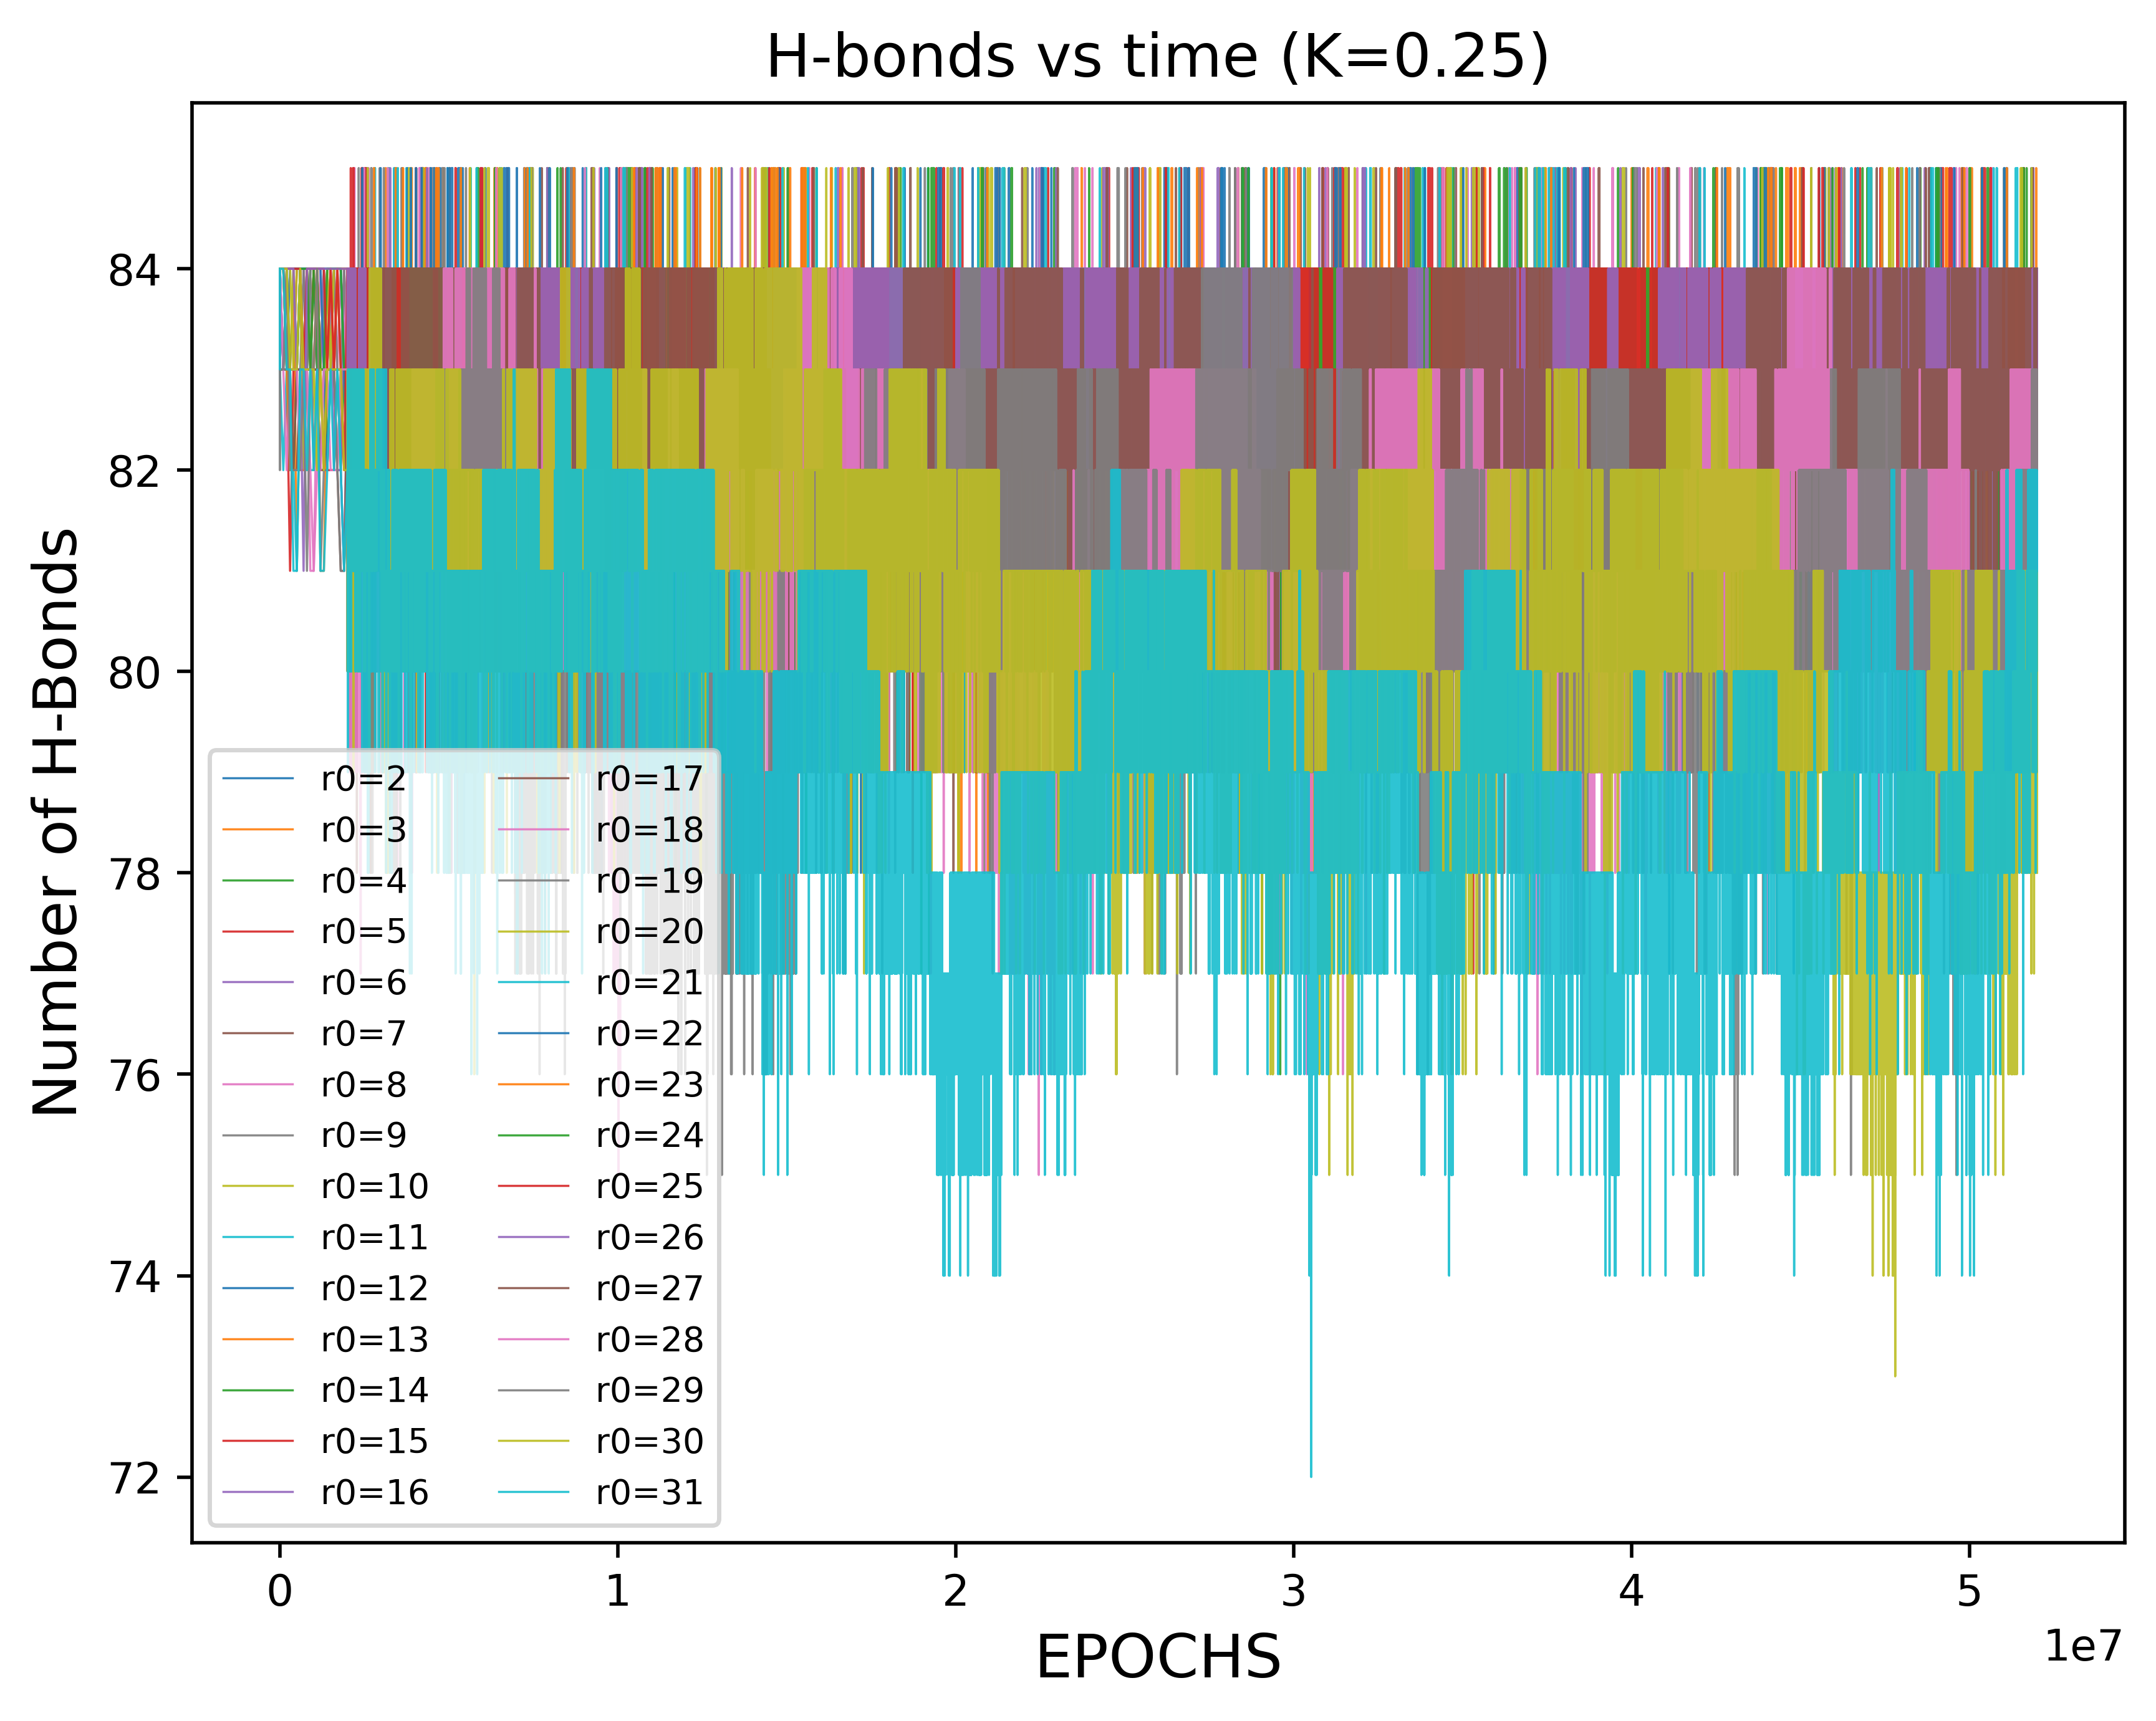

In [ ]:
#### PLOTTING H-BONDS VS TIME FOR DIFFERENT r0 AND SEED VALUES

for k in k_values:
    fig, ax = plt.subplots(figsize=(8,6), dpi=500)

    if k not in dfs:
        continue

    for r0 in r0_values:
        if r0 not in dfs[k]:
            continue
        for s, df in dfs[k][r0].items():
            ax.plot(df["step"], df["hbond"],
                    alpha=0.7, linewidth=0.5,
                    label=f"r0={r0}, seed={s}")

    ax.set_title(f"H-bonds vs time (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    # With many curves, legend can get huge; you can comment it out or shrink it:
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.show()

In [49]:
def steady_cutoff_by_hbonds(df,
                            tail_frac=0.10,
                            band=3.0,
                            min_stay=100000,
                            ):
    """
    Returns cutoff step where steady state begins, based on hbond convergence.
    df must have columns: 'step', 'hbond' (sorted by step).
    """
    d = df[["step", "hbond"]].dropna().sort_values("step").reset_index(drop=True)
    n = len(d)
    if n == 0:
        return None

    tail_n = int(n * tail_frac)
    plateau = d["hbond"].iloc[-tail_n:].median()  # robust plateau estimate

    in_band = (d["hbond"] >= plateau - band) & (d["hbond"] <= plateau + band)

    # Find earliest index i such that stable is True for the next min_stay points
    stable_run = in_band.rolling(min_stay, min_periods=min_stay).sum() >= min_stay
    idx = stable_run.idxmax() if stable_run.any() else None

    if idx is None:
        # fallback: if never "stays", cut at start of tail window
        return int(d["step"].iloc[-tail_n])

    # rolling window marks the END of the first full stable block; shift back
    start_idx = max(0, idx - (min_stay - 1))
    return int(d["step"].iloc[start_idx])

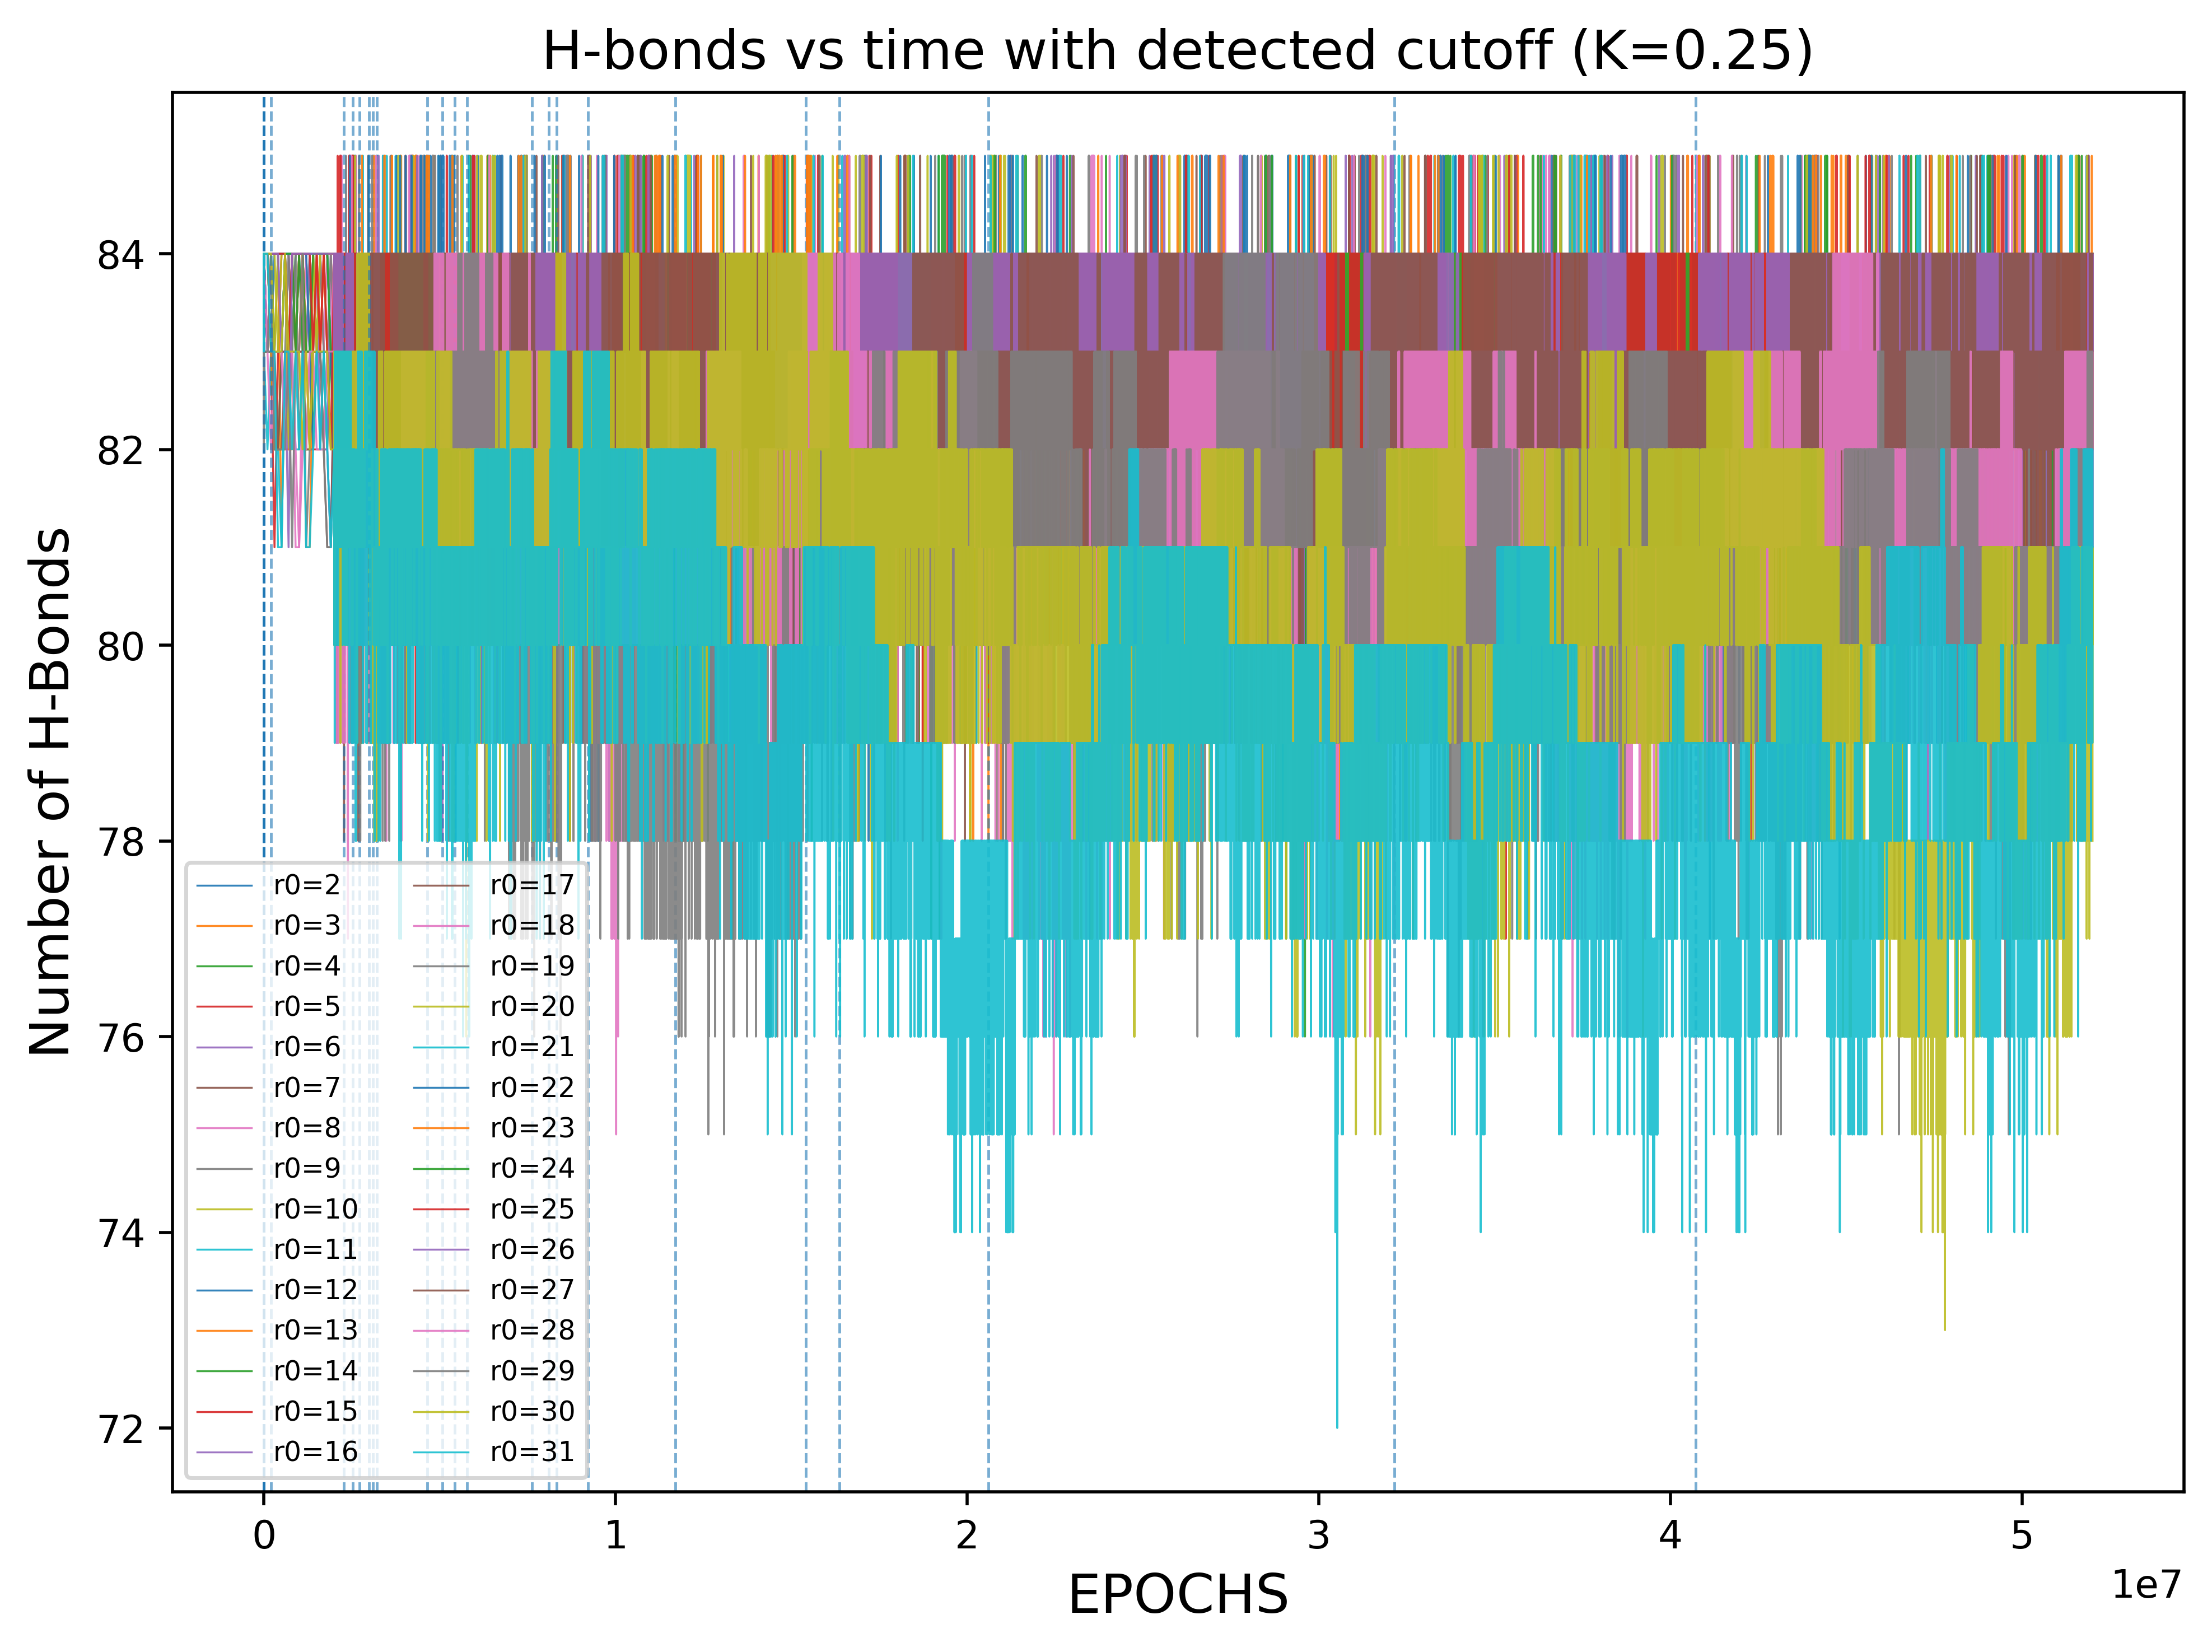

In [ ]:
import matplotlib.pyplot as plt

source = dfs

# Parameters for cutoff detection
TAIL_FRAC = 0.10
BAND = 4.0
MIN_STAY_STEPS = 5000  # adjust (e.g. 1e6 or 2e6)

cutoffs = {}      # cutoffs[k][r0][seed] = cutoff_step
dfs_ss = {}       # steady-state cropped dfs: dfs_ss[k][r0][seed]

for k, by_r0 in source.items():
    cutoffs[k] = {}
    dfs_ss[k] = {}
    for r0, by_seed in by_r0.items():
        cutoffs[k][r0] = {}
        dfs_ss[k][r0] = {}
        for s, df in by_seed.items():
            c = steady_cutoff_by_hbonds(
                df,
                tail_frac=TAIL_FRAC,
                band=BAND,
                min_stay=MIN_STAY_STEPS,
            )
            cutoffs[k][r0][s] = c
            dfs_ss[k][r0][s] = df[df["step"] >= c].reset_index(drop=True)

# ---- Plot hbonds time series with vertical cutoff lines (one figure per k) ----
for k, by_r0 in source.items():
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

    for r0, by_seed in by_r0.items():
        for s, df in by_seed.items():
            ax.plot(df["step"], df["hbond"], linewidth=0.5, alpha=0.9, label=f"r0={r0}, seed={s}")

            c = cutoffs[k][r0][s]
            ax.axvline(c, linestyle="--", linewidth=0.7, alpha=0.6)

    ax.set_title(f"H-bonds vs time with detected cutoff (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.tight_layout()
    plt.show()

In [ ]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_ss.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

       k   r_0    F mean     F std  |F| mean   |F| std  dist mean  dist std  \
0   0.25   2.0  0.194603  0.147770  0.206744  0.130243   2.778414  0.591078   
1   0.25   3.0  0.186921  0.165761  0.203185  0.145369   3.747685  0.663046   
2   0.25   4.0  0.177790  0.151469  0.195113  0.128387   4.711160  0.605876   
3   0.25   5.0  0.165294  0.152884  0.186986  0.125426   5.661175  0.611534   
4   0.25   6.0  0.153479  0.162561  0.179434  0.133361   6.613915  0.650244   
5   0.25   7.0  0.148869  0.153518  0.175948  0.121539   7.595474  0.614072   
6   0.25   8.0  0.137362  0.153520  0.168341  0.118735   8.549447  0.614081   
7   0.25   9.0  0.134827  0.156407  0.168210  0.119779   9.539308  0.625629   
8   0.25  10.0  0.128315  0.155204  0.163738  0.117230  10.513259  0.620815   
9   0.25  11.0  0.124328  0.158073  0.162099  0.119032  11.497311  0.632294   
10  0.25  12.0  0.120417  0.156028  0.159680  0.115531  12.481667  0.624114   
11  0.25  13.0  0.116182  0.154989  0.156818  0.1137

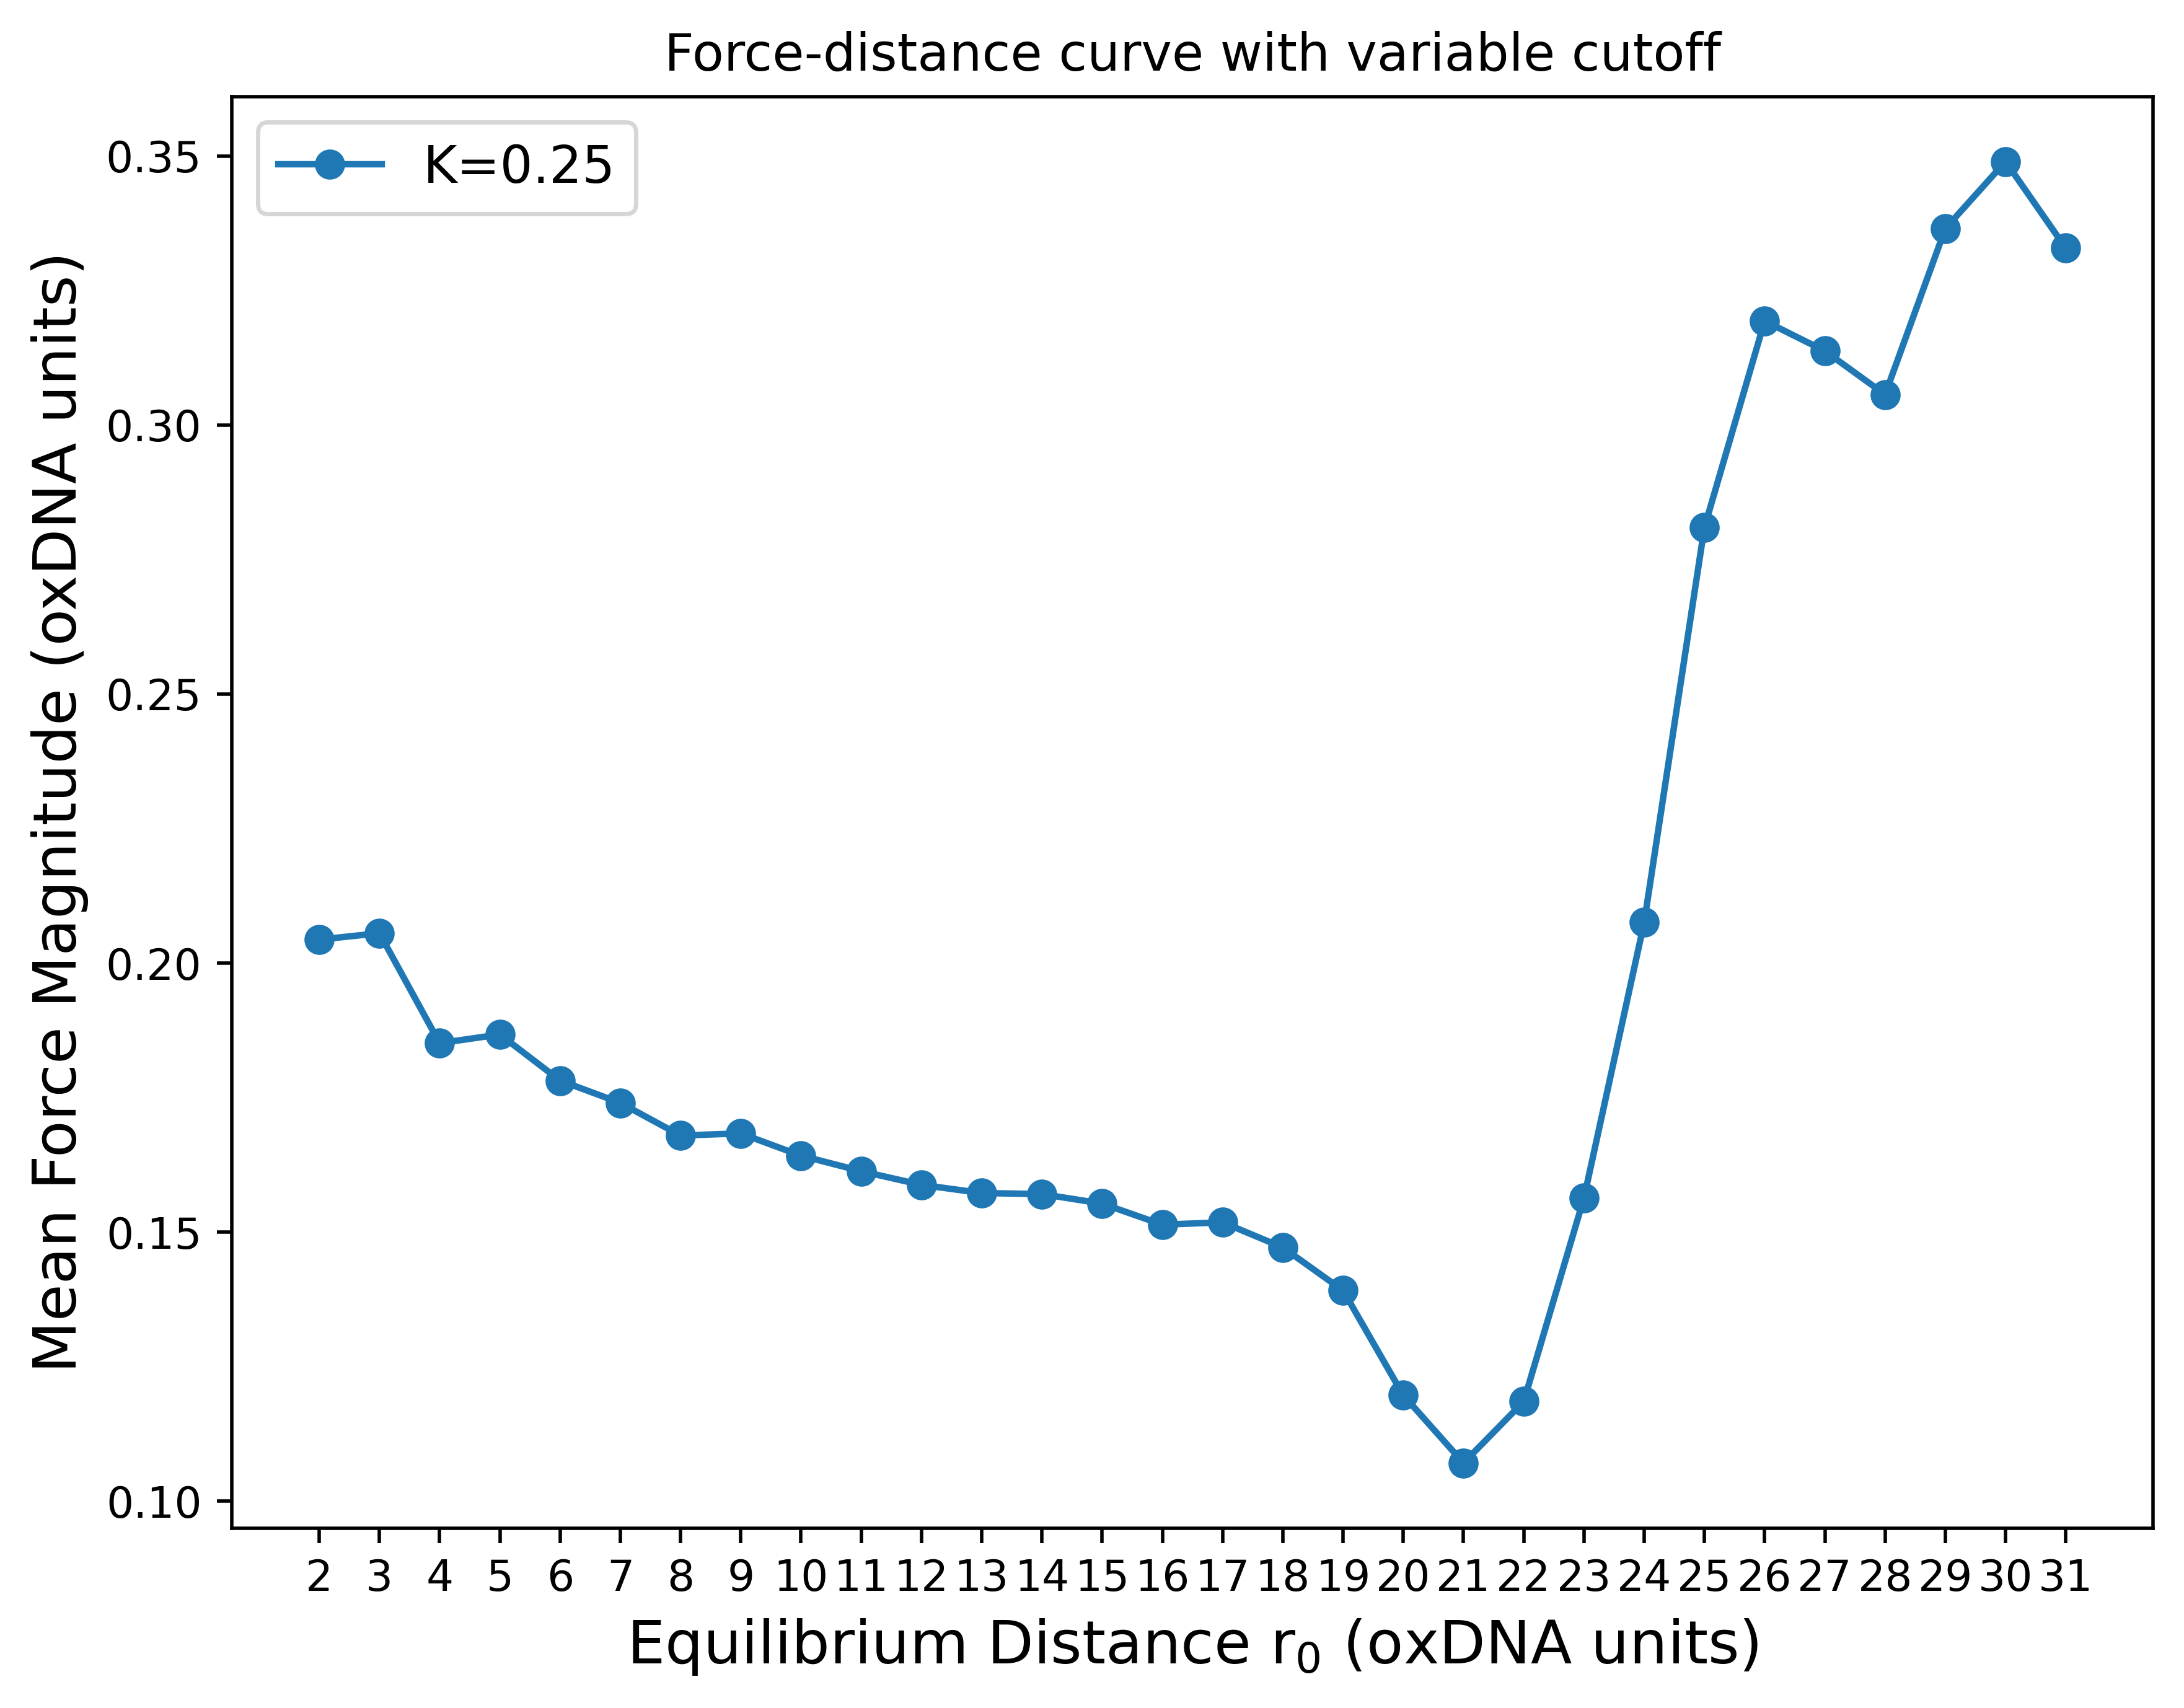

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with variable cutoff")
ax.legend(fontsize=12)

plt.show()

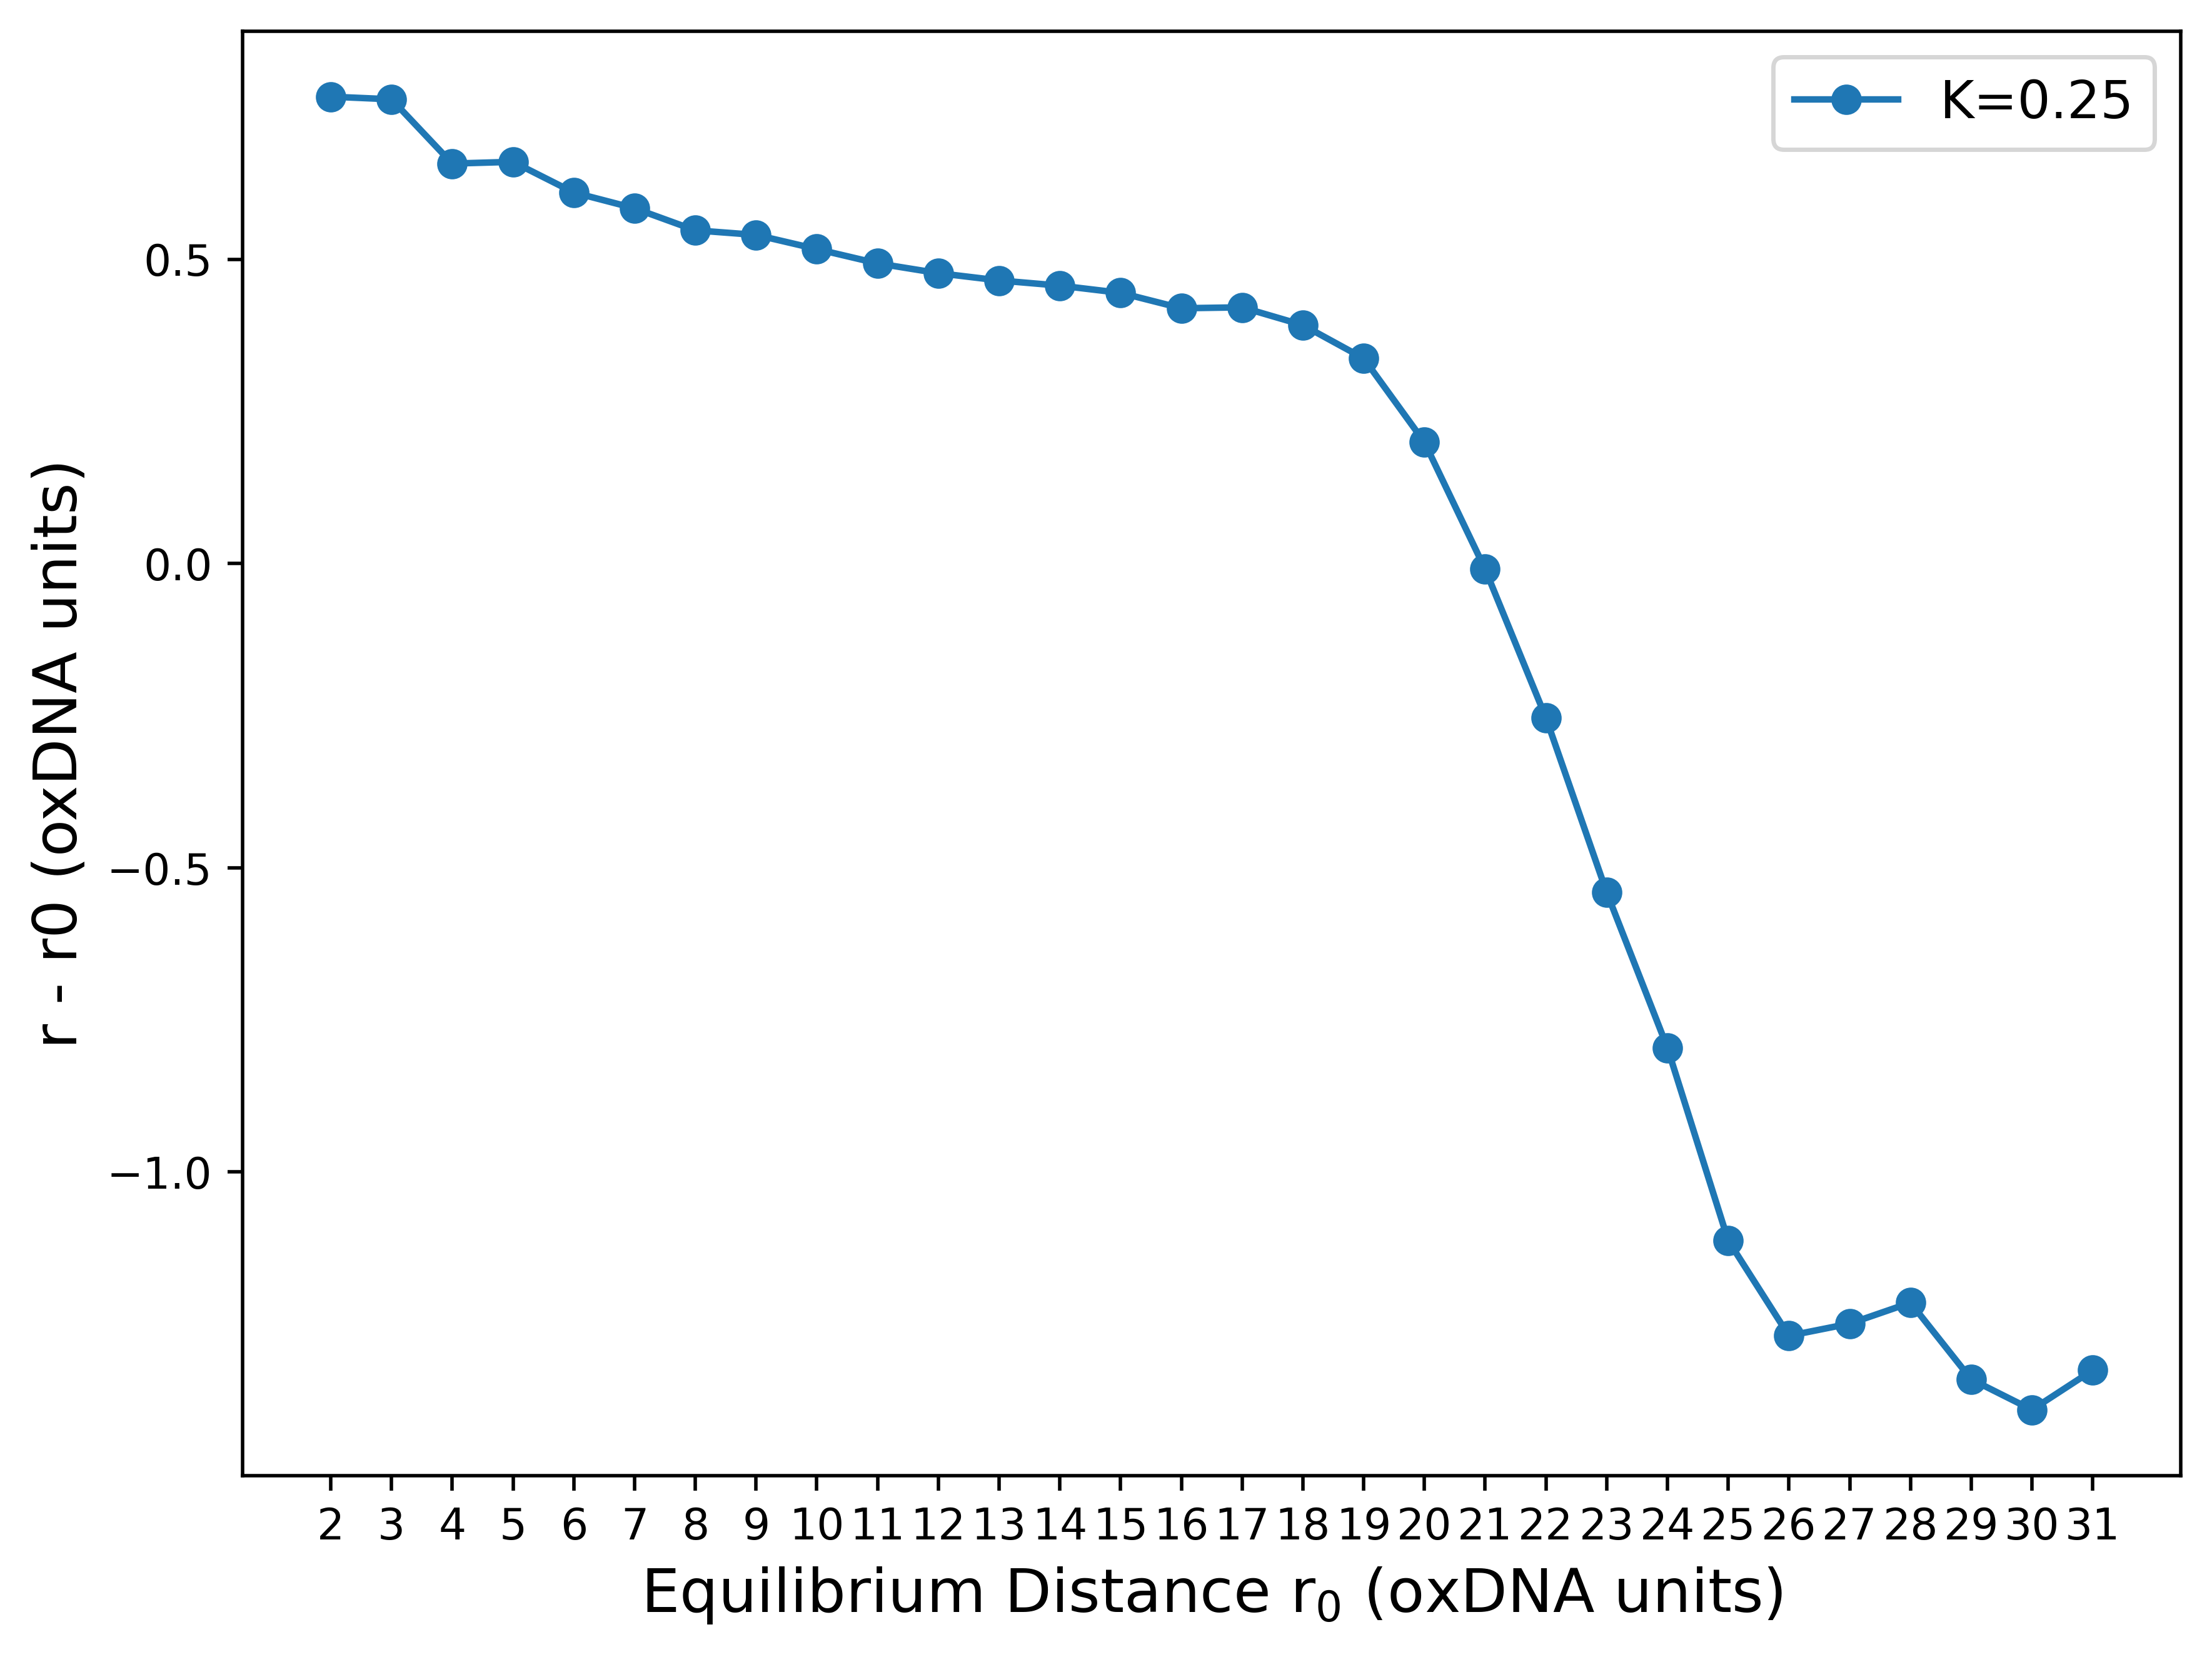

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

In [ ]:
CUTOFF = 1.5e7  # 2,500,000

dfs_cfiltered = {}  # dfs_cfiltered[k][r0][seed] = cutoff-filtered df

for k, by_r0 in dfs.items():
    dfs_cfiltered[k] = {}
    for r0, by_seed in by_r0.items():
        dfs_cfiltered[k][r0] = {}
        for s, df in by_seed.items():
            dfs_cfiltered[k][r0][s] = df[df["step"] >= CUTOFF].reset_index(drop=True)

In [ ]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_cfiltered.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

       k   r_0    F mean     F std  |F| mean   |F| std  dist mean  dist std  \
0   0.25   2.0  0.191758  0.147704  0.204375  0.129688   2.767033  0.590818   
1   0.25   3.0  0.190683  0.151793  0.205558  0.130946   3.762733  0.607171   
2   0.25   4.0  0.164269  0.151594  0.185127  0.125272   4.657078  0.606378   
3   0.25   5.0  0.164997  0.152767  0.186738  0.125262   5.659987  0.611066   
4   0.25   6.0  0.152404  0.153415  0.178180  0.122537   6.609617  0.613660   
5   0.25   7.0  0.145913  0.153616  0.174027  0.120843   7.583652  0.614464   
6   0.25   8.0  0.136850  0.153434  0.167964  0.118566   8.547401  0.613734   
7   0.25   9.0  0.134973  0.156370  0.168351  0.119697   9.539893  0.625482   
8   0.25  10.0  0.129148  0.155215  0.164219  0.117486  10.516591  0.620862   
9   0.25  11.0  0.123274  0.155682  0.161336  0.115776  11.493096  0.622729   
10  0.25  12.0  0.119255  0.155328  0.158790  0.114604  12.477019  0.621311   
11  0.25  13.0  0.116265  0.155303  0.157276  0.1135

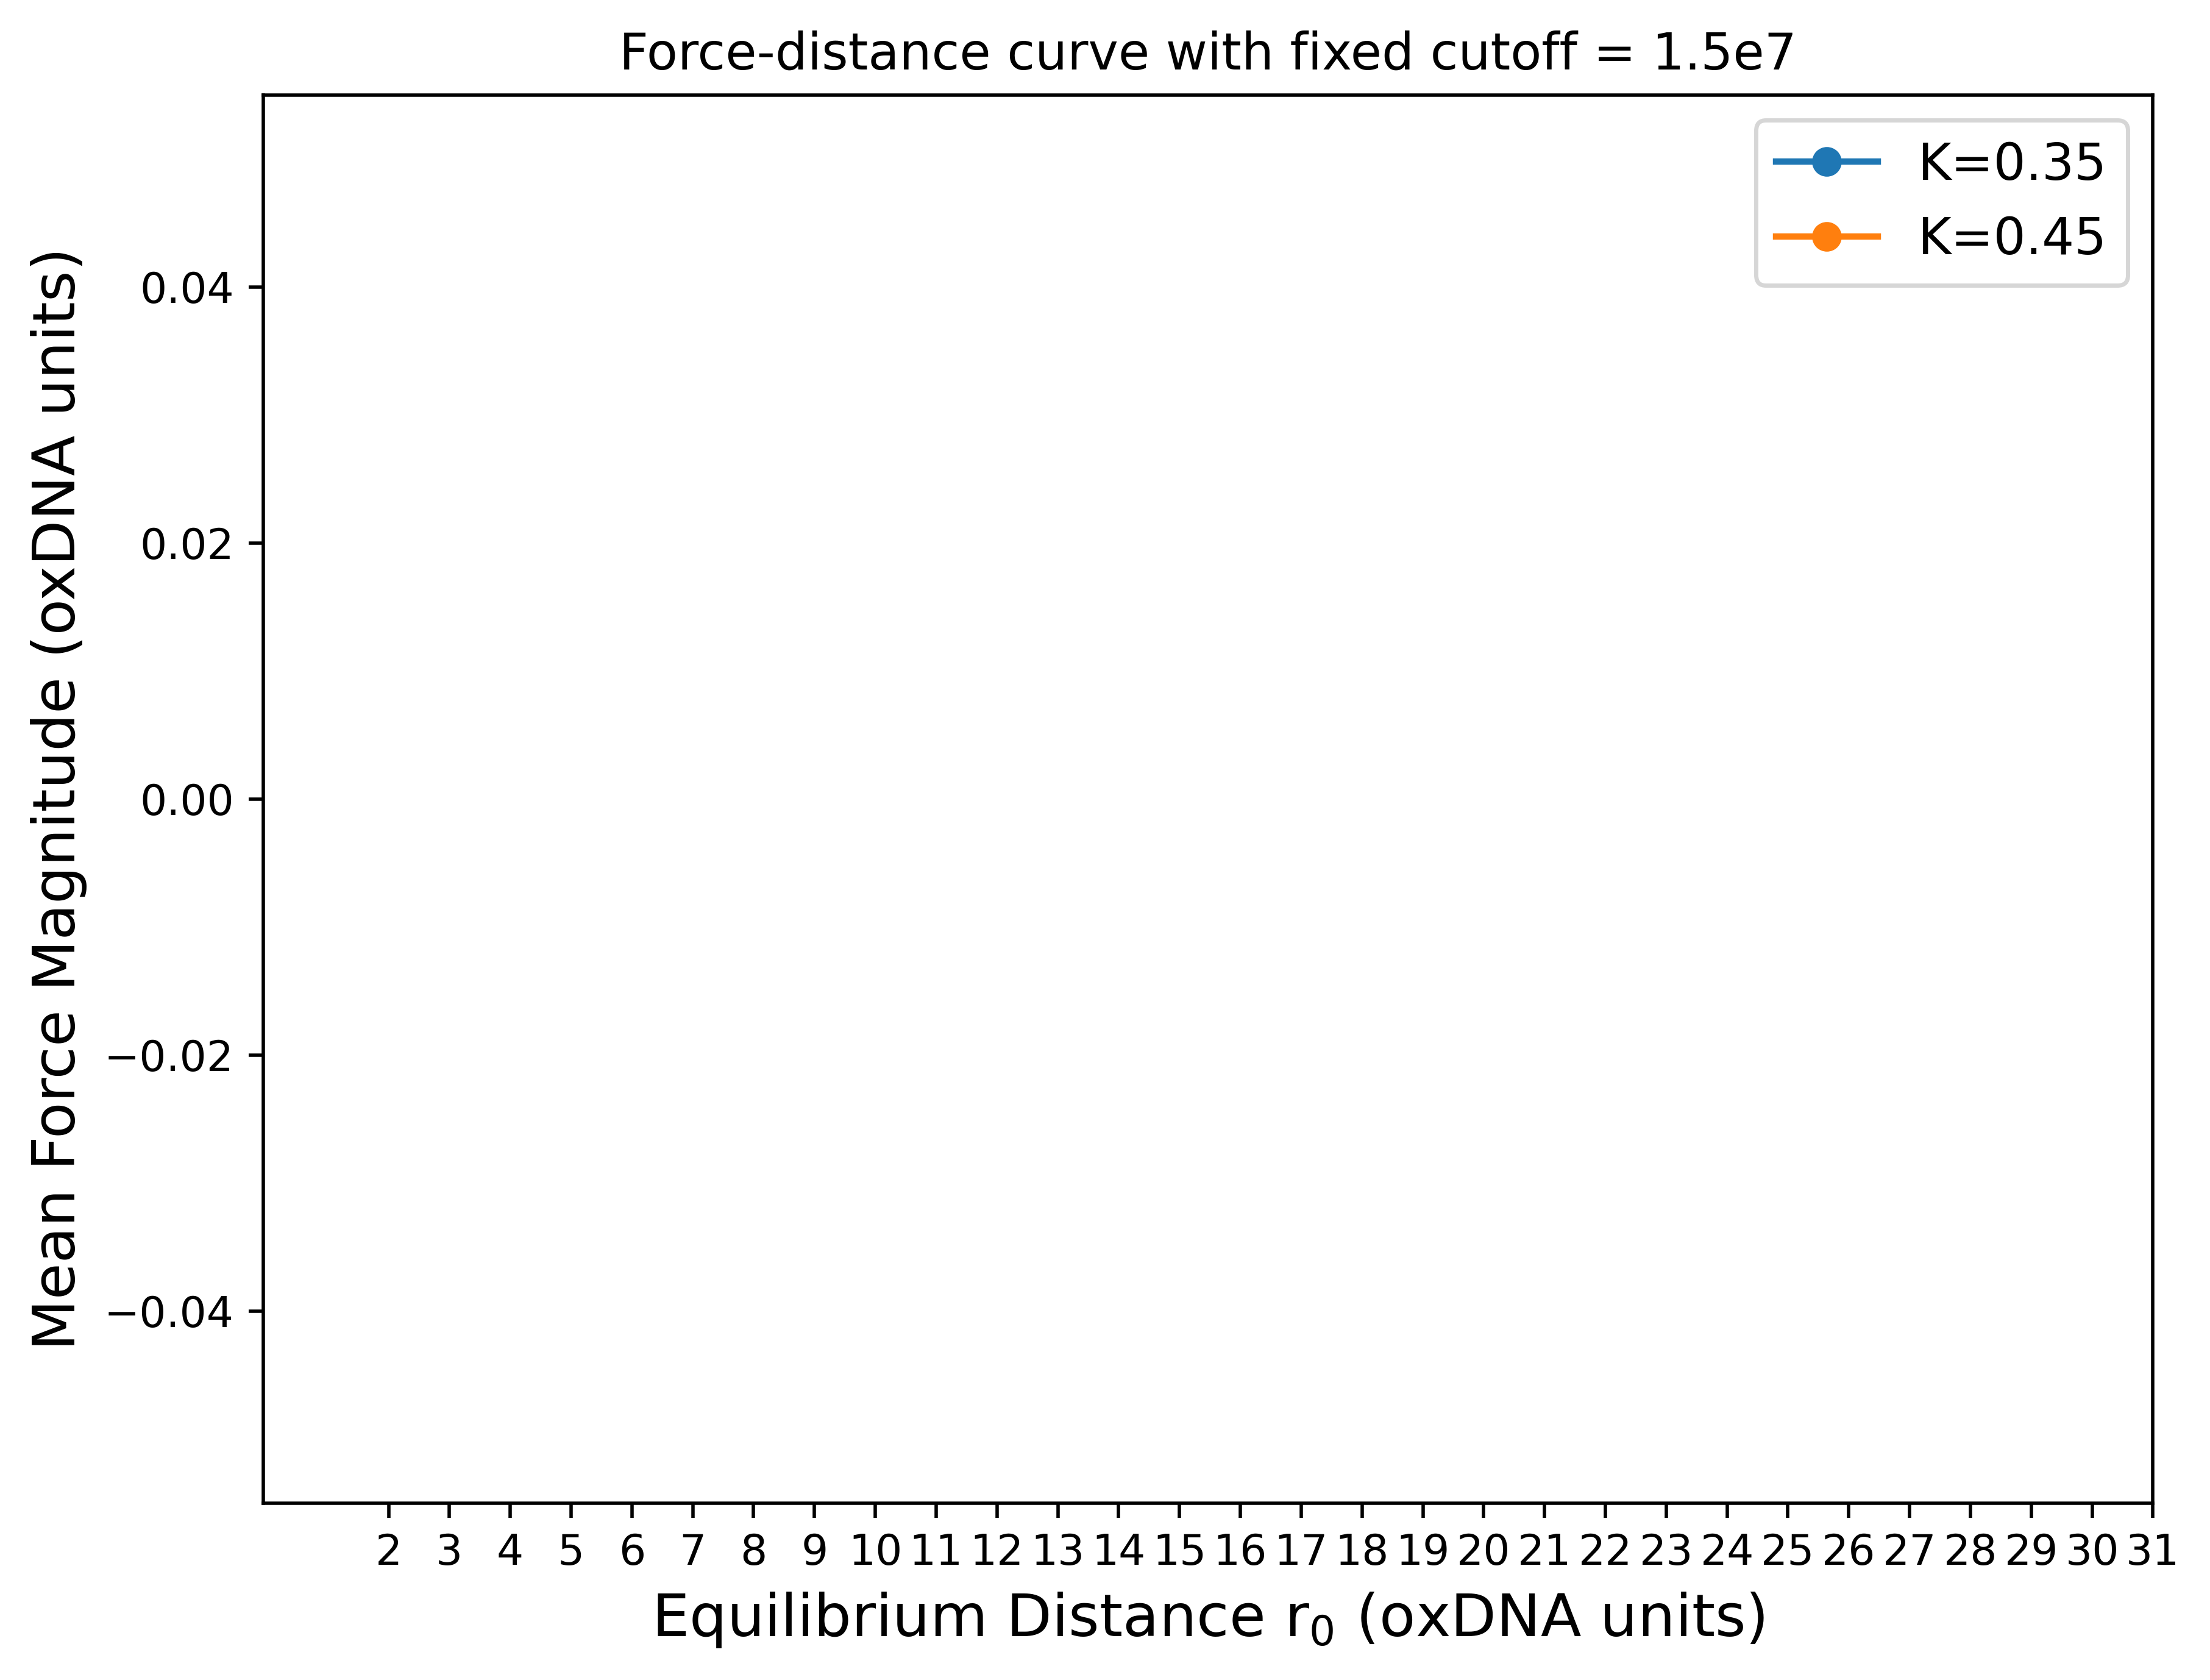

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with fixed cutoff = 1.5e7")
ax.legend(fontsize=12)

plt.show()

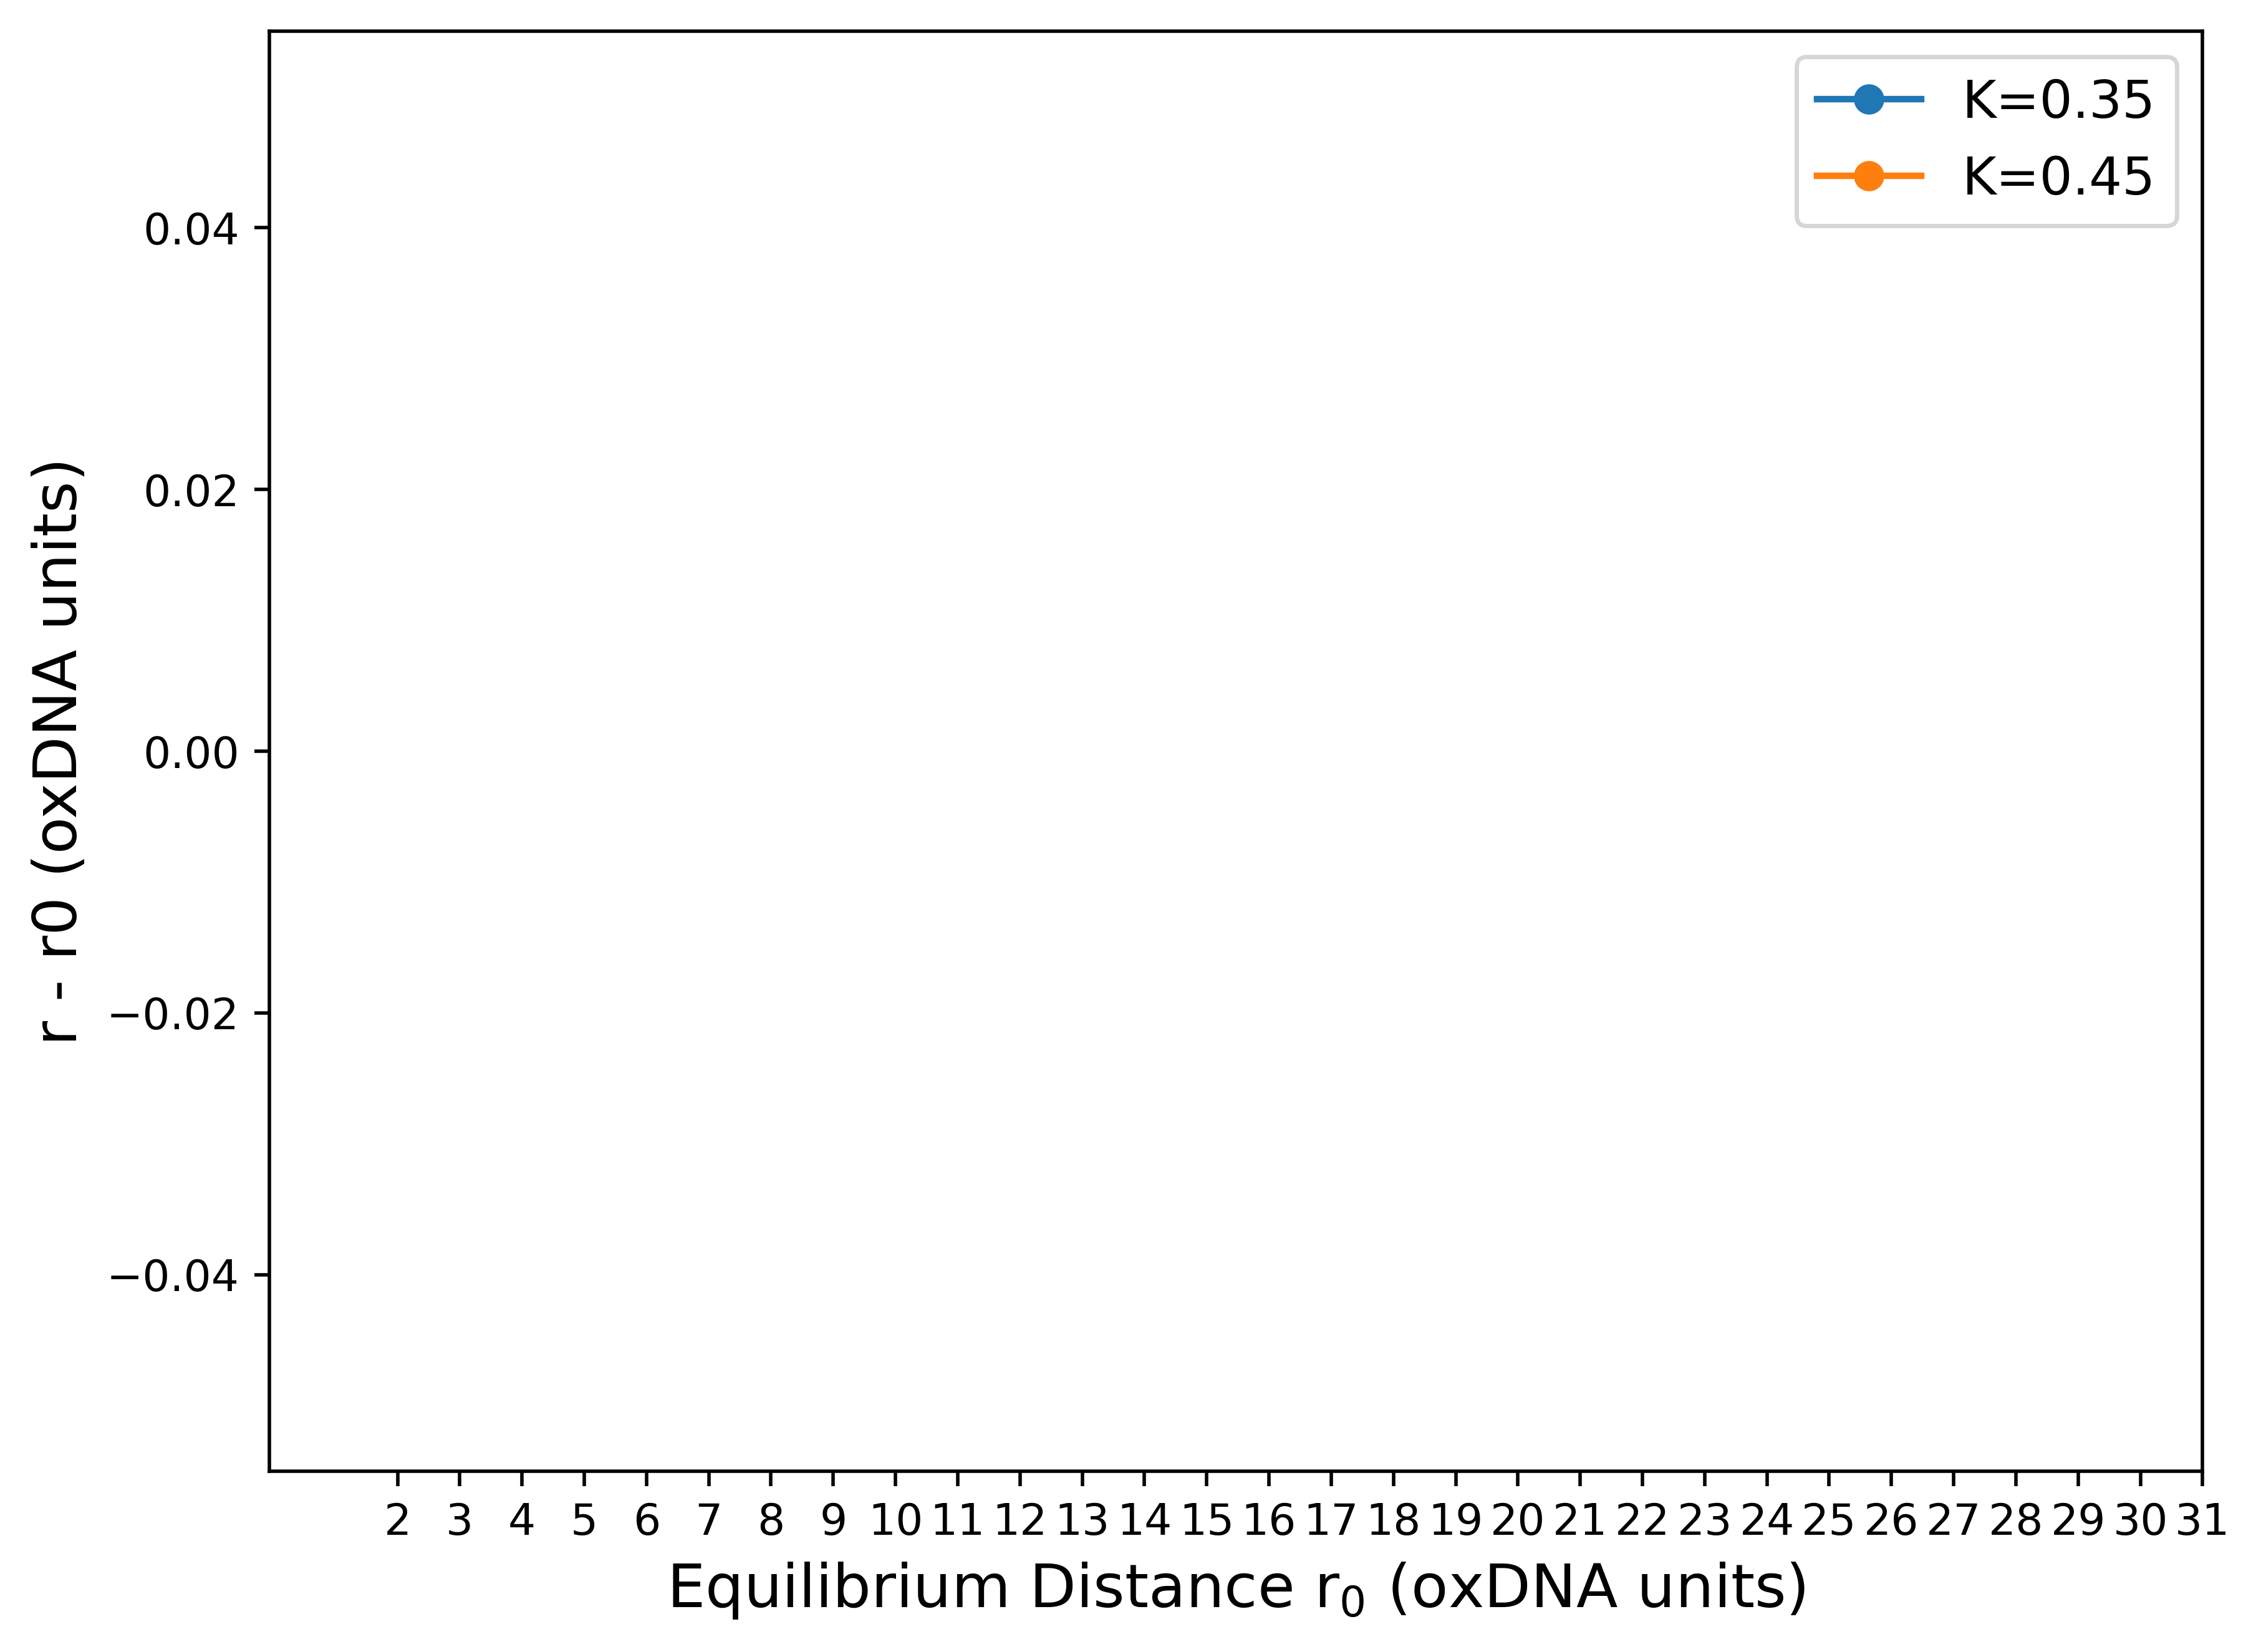

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

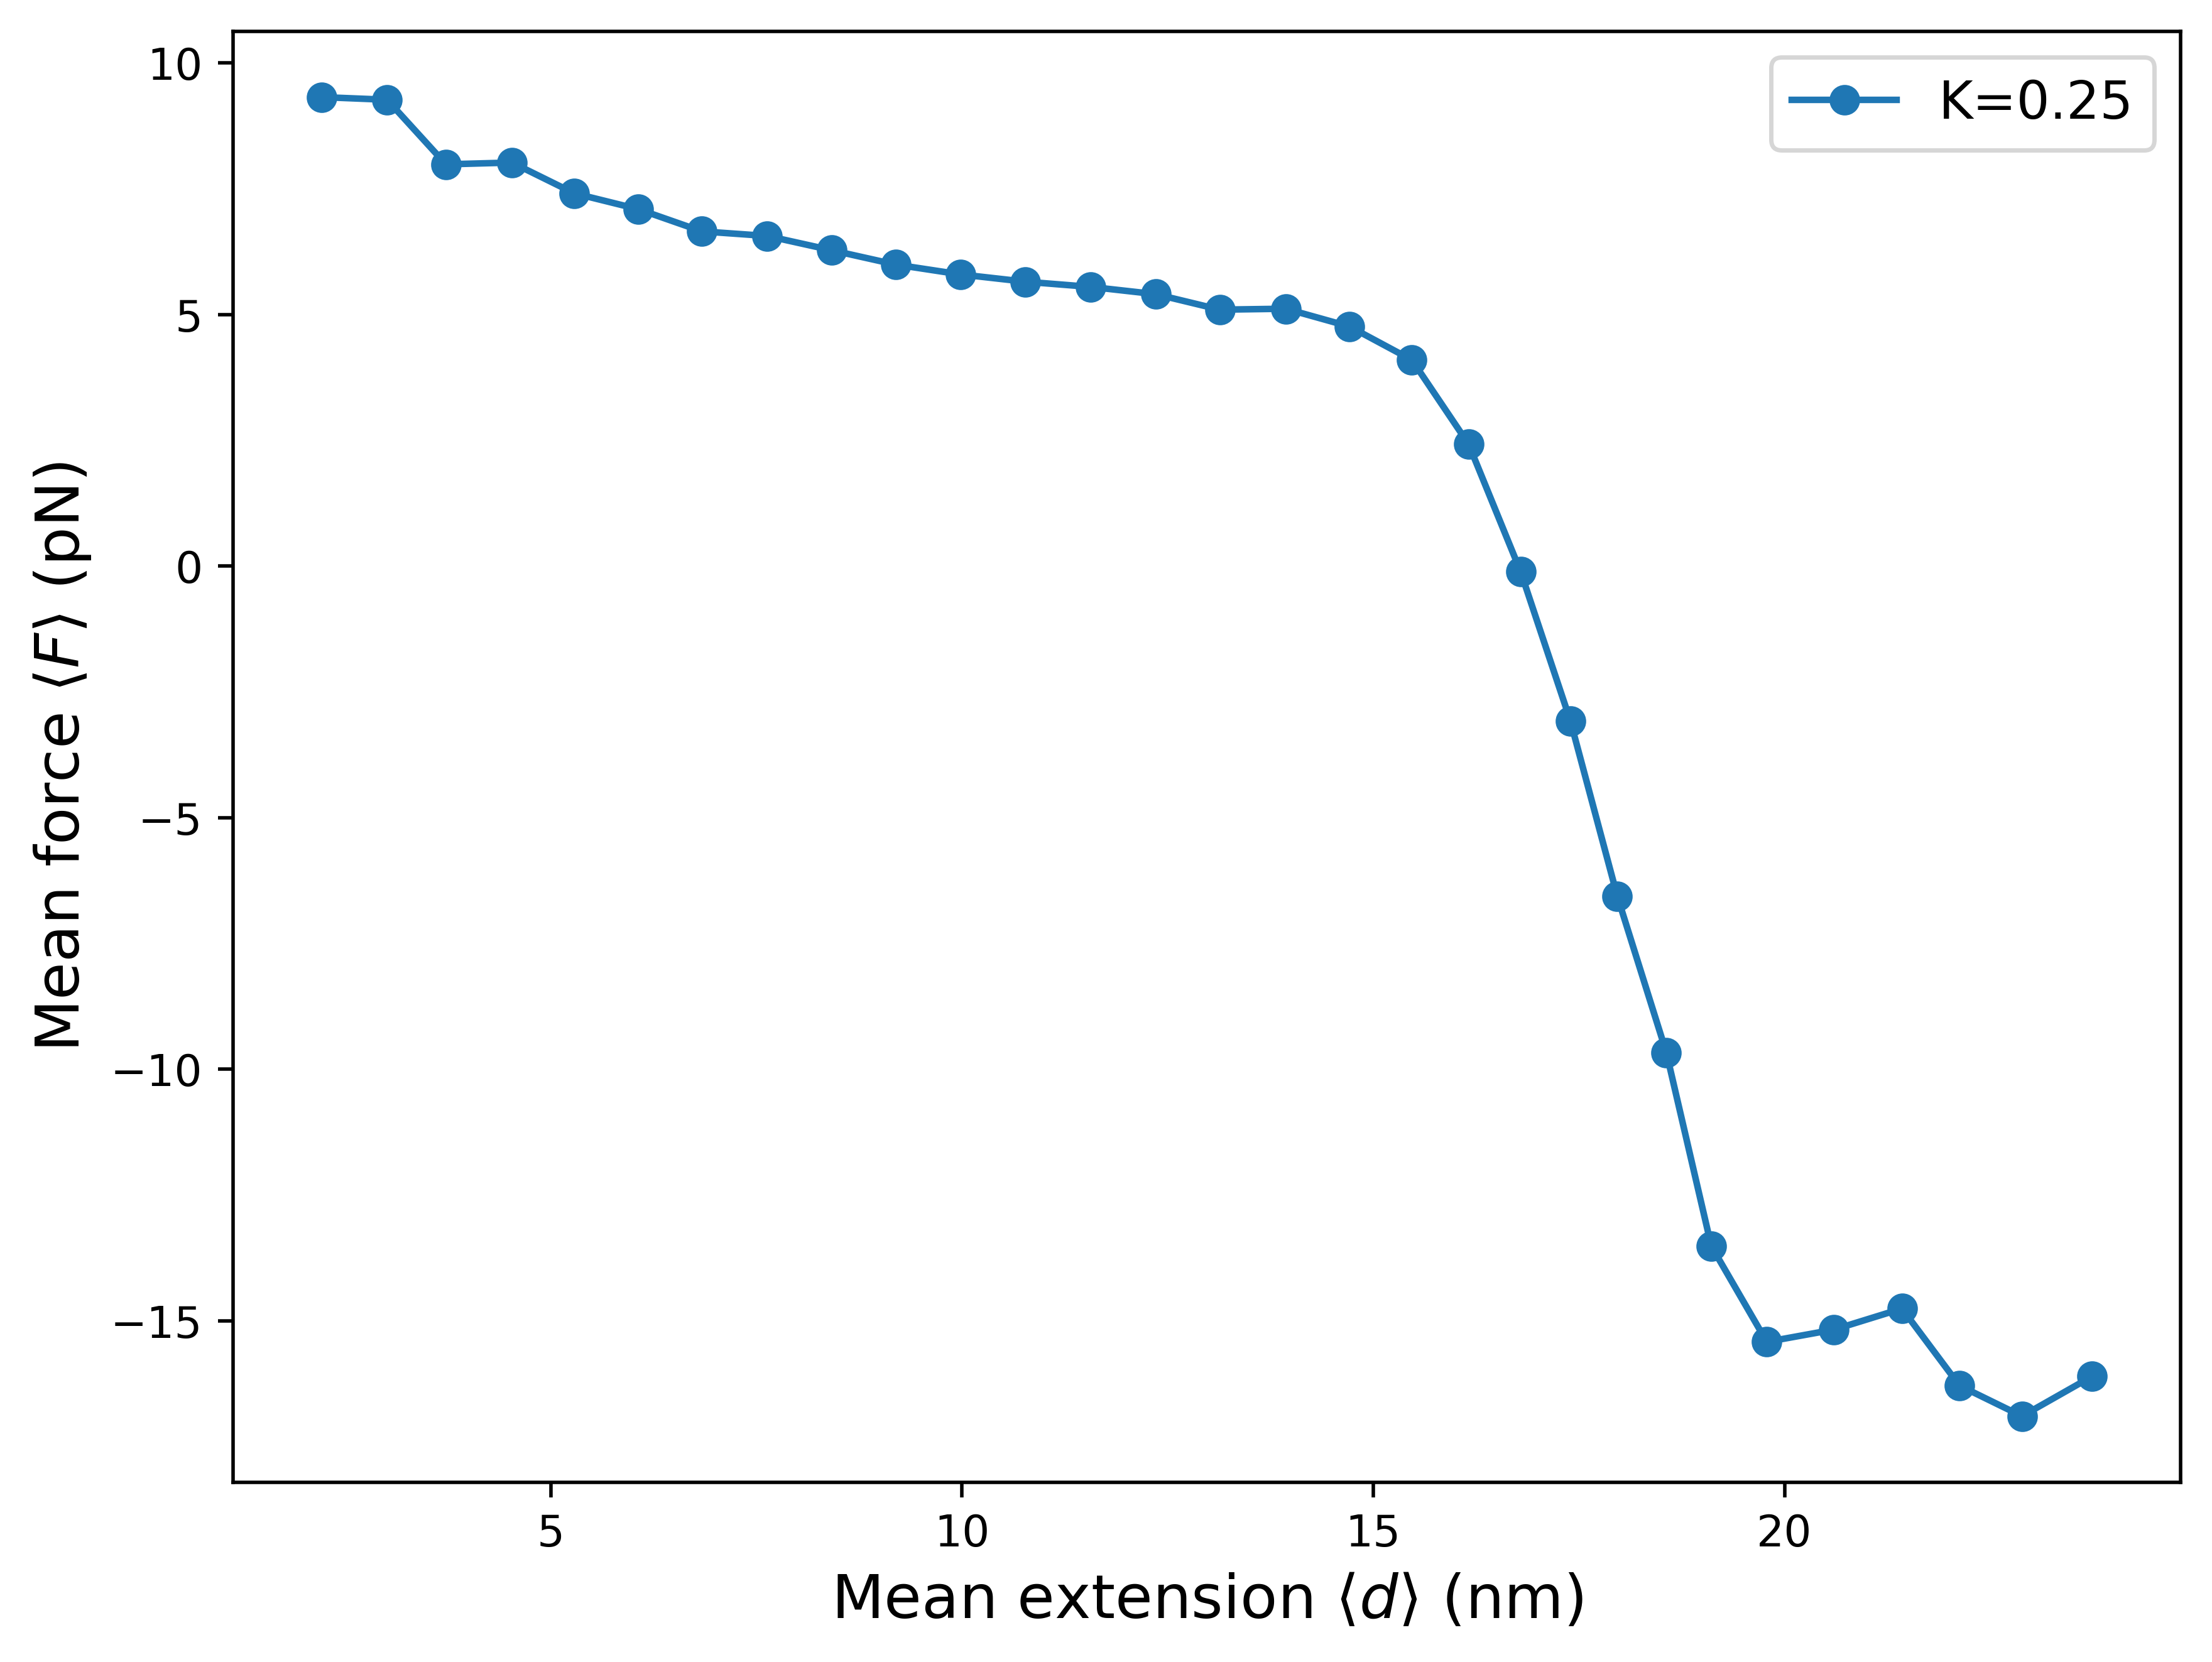

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("dist mean")
        ax.plot(0.8*sub["dist mean"], 48.6*sub["F mean"], marker="o", label=f"{label}, seed={s}")

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)", fontsize=14)
ax.legend(fontsize=12)

plt.show()